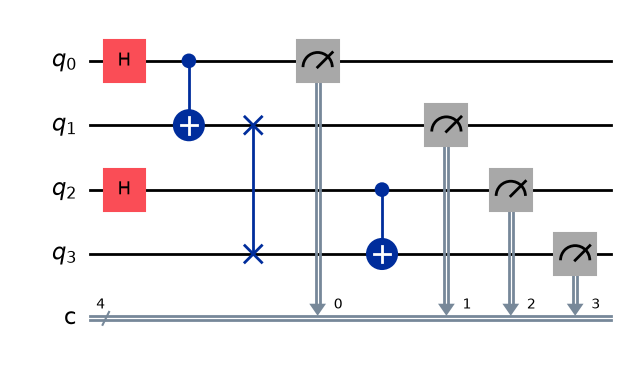

In [13]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

# 4 qubits, 4 classical bits
qc = QuantumCircuit(4, 4)

# -------------------------
# Module A: q0, q1
# -------------------------

# -------------------------
# Module B: q2, q3
# -------------------------

qc.h(0)
qc.cx(0, 1)

qc.h(2)
qc.swap(1, 3)
qc.cx(2, 3)


#
# Connection q1, q2
#




# -------------------------
# Measure
# -------------------------

qc.measure(range(4), range(4))

qc.draw("mpl")


In [14]:
# -------------------------
# Simulate
# -------------------------

simulator = AerSimulator()

result = simulator.run(
    qc,
    shots=10_000
).result()

counts = result.get_counts()

print(counts)

{'0101': 2461, '0000': 2497, '1100': 2467, '1001': 2575}


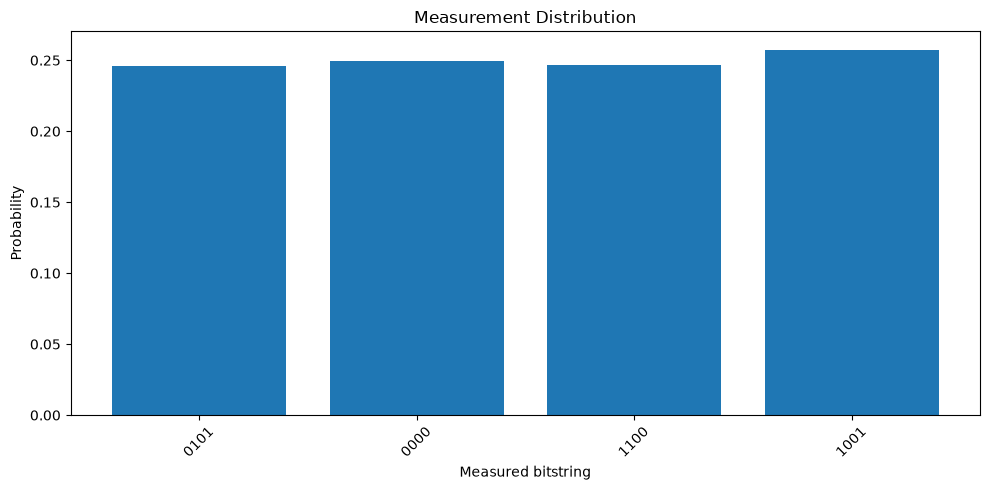

In [15]:
import matplotlib.pyplot as plt

bitstrings = list(counts.keys())

probabilities = [
    counts[x] / 10_000
    for x in bitstrings
]

plt.figure(figsize=(10, 5))

plt.bar(bitstrings, probabilities)

plt.xlabel("Measured bitstring")
plt.ylabel("Probability")
plt.title("Measurement Distribution")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()